# 06 · Pricing and promotion scenarios

Using the F3 estimates from notebook 03, this notebook compares price and promotion scenarios and shows how many training observations support each combination. Section 4 compares TPR and display at the same 20% discount.

The script `scripts/fit_scenarios.py` refitted F3 by REML on the training weeks (0 to 103). It stored the coefficients, joint covariance, scenario table and reconciliation with notebook 03 in `outputs/runs`. Both language versions read this refit and the original F3 run. The estimates describe conditional associations in weeks with recorded sales.

*Data: dunnhumby Source Files – Breakfast at the Frat.*

In [1]:
LANG = "en"

In [2]:
import warnings

import pandas as pd
from IPython.display import display

from retail_multilevel import interpret, viz
from retail_multilevel.i18n import localize_columns, scenario_label, t
from retail_multilevel.runs import load_run

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", "{:,.3f}".format)
scen = load_run("p2_scenarios", "20261124-220614-acbfe8b9")
fixed = load_run("fixed_effects", "20261124-114202-1fda5a5d")
print(t("data_credit", LANG))
stored = {"p2_scenarios": scen, "fixed_effects": fixed}
display(pd.DataFrame({k: {"run_id": r.run_id, "finished_at": r.metadata["finished_at"]} for k, r in stored.items()}).T)


def localized(df):
    out = df.copy()
    if "scenario" in out:
        out["scenario"] = [scenario_label(x, LANG) for x in out["scenario"]]
    if "term" in out:
        out["term"] = [viz.term_label(x, LANG) for x in out["term"]]
    return localize_columns(out, LANG)

Data: dunnhumby Source Files – Breakfast at the Frat


,run_id,finished_at
p2_scenarios,20261124-220614-acbfe8b9,2026-11-24T22:08:13.369259
fixed_effects,20261124-114202-1fda5a5d,2026-11-24T11:45:14.599134


The two runs that were read are identified above (identifier and finish time), and the identifiers are fixed in the code, so re-running the notebook always reads the same artefacts.

## 1. The question and the definition of the scenarios

The reference is a regular week with no discount or promotion. Each scenario estimates how much modelled sales differ from that week and checks support for the combination in training. For a discount d and indicators for feature f, display s and TPR r, the difference in log(units) is Δlog = β_discount · log(1 − d) + β_feature · f + β_display · s + β_TPR · r. Base price and other controls are held constant. The formula `100 × expm1(Δlog)` expresses the percentage change associated with the modelled sales ratio. The `TPR_ONLY` indicator represents a temporary price reduction without feature or display. The table shows how the eight scenarios apply that rule.

Notebook 03 registered all eight scenarios before the contrast results in notebook 05.

In [3]:
design = pd.DataFrame(interpret.DEFAULT_SCENARIOS, columns=["scenario", "discount", "feature", "display", "tpr"])
display(localized(design.assign(discount=design["discount"] * 100)))

,Scenario,Discount (%),Feature,Display,TPR
0,"Regular week (no discount, no promotion)",0.000,0,0,0
1,TPR with 10% discount,10.000,0,0,1
2,TPR with 20% discount,20.000,0,0,1
3,"Feature, no discount",0.000,1,0,0
4,Feature with 20% discount,20.000,1,0,0
5,"Display, no discount",0.000,0,1,0
6,Display with 20% discount,20.000,0,1,0
7,Feature and display with 25% discount,25.000,1,1,0


The pointwise 95% intervals use the joint covariance of the F3 coefficients fitted by REML with `lme4` (Bates et al., 2015). This matrix gives the standard error of the linear combination Δlog and accounts for covariance between coefficients. The interval limits are back-transformed with the same formula used for the percentage effect.

## 2. Reconciliation with notebook 03

The table checks whether the 14 coefficients from the refit that produced the joint covariance match the stored F3 coefficients from notebook 03.

In [4]:
recon = scen.load_table("reconciliation")
with pd.option_context("display.float_format", "{:,.6f}".format):
    display(localized(recon))
info = scen.load_json("reconciliation")
display(
    localize_columns(
        pd.DataFrame(
            [
                {
                    "nobs": info["nobs"],
                    "max_week": info["max_week"],
                    "messages": info["n_messages"],
                    "coef_max_abs_diff": info["coef_max_abs_diff"],
                    "effect_diff_pp": info["scenario_effect_max_abs_diff_pp"],
                }
            ]
        ),
        LANG,
    )
)

,Term,Stored estimate (notebook 03),Refit estimate,Absolute difference
0,Intercept,2.961001,2.961001,0.000000
1,Seasonality: cosine 1,0.033744,0.033744,0.000000
2,Seasonality: cosine 2,0.014809,0.014809,0.000000
3,Seasonality: cosine 3,0.010688,0.010688,0.000000
4,In-store display,0.408673,0.408673,0.000000
5,Feature (flyer),0.497244,0.497244,0.000000
6,"Regular price, within pair (log)",-1.592098,-1.592098,0.000000
7,"Regular price, pair mean (log)",-0.879671,-0.879671,0.000000
8,Discount depth (log price / base),-1.685184,-1.685184,0.000000
9,Seasonality: sine 1,-0.001711,-0.001711,0.000000


,Observations,Last week,Convergence messages,Max. absolute coefficient difference,Max. absolute effect difference (pp)
0,347092,103,0,0.000,0.000


The refit uses the same 347,092 rows of weeks 0 to 103, converges with no messages and reproduces the 14 stored coefficients, with a maximum absolute difference of 0.0 (the tolerance of the script was 1e-6). The point effects of the scenarios also coincide with those computed, by the scenario function of notebook 03, from the stored coefficients, with a maximum difference of 0.0 percentage points. The values and the meaning of the estimates are therefore those of notebook 03: the same linear combination of coefficients, on the same scale. What is added is the joint covariance, which allows the intervals that notebook 03 could not present.

## 3. The scenarios

The table below gives, for each scenario, the discount, the modelled change in sales relative to the regular week and the pointwise 95% interval, and, in a second table, the log difference and its standard error. The chart shows the same effects beside the observed support of each scenario in the training rows.

,Scenario,Discount (%),Modelled change in sales (%),Lower 95% (%),Upper 95% (%)
0,"Regular week (no discount, no promotion)",0.000,0.000,0.000,0.000
1,TPR with 10% discount,10.000,14.605,13.910,15.304
2,TPR with 20% discount,20.000,39.767,38.998,40.541
3,"Feature, no discount",0.000,64.418,63.046,65.802
4,Feature with 20% discount,20.000,139.476,137.785,141.179
5,"Display, no discount",0.000,50.482,49.422,51.549
6,Display with 20% discount,20.000,119.177,117.664,120.701
7,Feature and display with 25% discount,25.000,301.772,298.699,304.868


,Scenario,Log difference,SE (joint covariance)
0,"Regular week (no discount, no promotion)",0.0000,0.0000
1,TPR with 10% discount,0.1363,0.0031
2,TPR with 20% discount,0.3348,0.0028
3,"Feature, no discount",0.4972,0.0043
4,Feature with 20% discount,0.8733,0.0036
5,"Display, no discount",0.4087,0.0036
6,Display with 20% discount,0.7847,0.0035
7,Feature and display with 25% discount,1.3907,0.0039


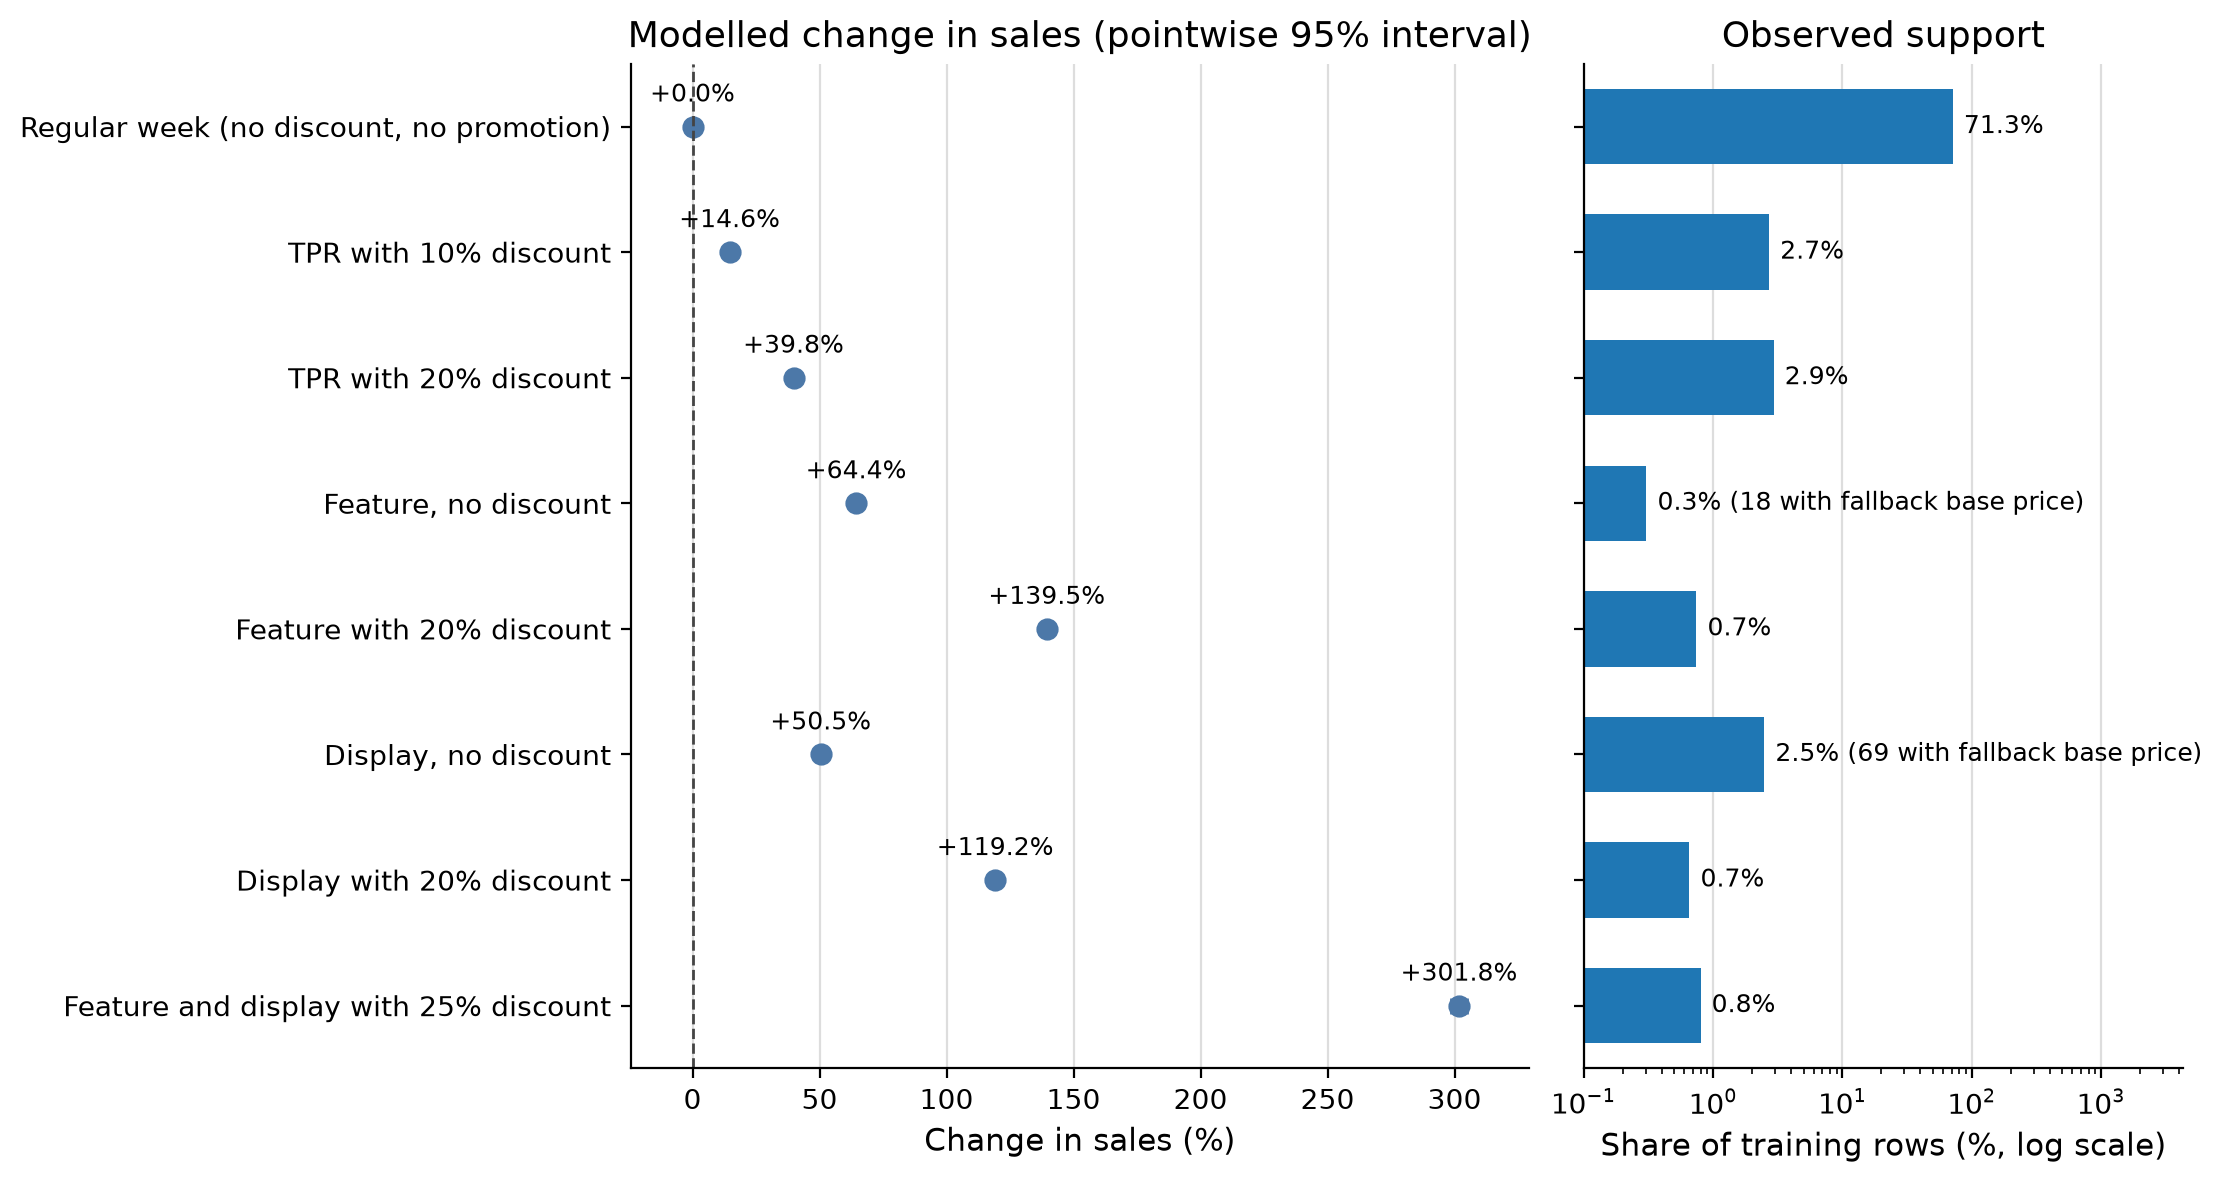

In [5]:
scenarios = scen.load_table("scenarios")
effects = scenarios.assign(discount=scenarios["discount"] * 100)[
    ["scenario", "discount", "effect_pct", "ci_low_pct", "ci_high_pct"]
]
display(localized(effects))
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(localized(scenarios[["scenario", "dlog", "se"]]))
fig = viz.plot_scenario_effects(scenarios, LANG)

The regular week has zero contrast, as it should. A TPR with a 10% discount is associated with a modelled change of +14.6% in sales (interval from 13.9% to 15.3%), and with a 20% discount, of +39.8% (from 39.0% to 40.5%). Feature without discount has +64.4% (from 63.0% to 65.8%), and with a 20% discount, +139.5% (from 137.8% to 141.2%). Display without discount has +50.5% (from 49.4% to 51.5%), and with a 20% discount, +119.2% (from 117.7% to 120.7%). Feature with display and a 25% discount has +301.8% (from 298.7% to 304.9%).

These values depend on the functional form: the elasticity is constant in log(1 − d), the discount and the modalities are additive on the logarithmic scale, and no interaction between feature and display is estimated. The value of the combined scenario, for instance, is the product of the separately estimated effects. The intervals are narrow because they reflect only the variability conditional on the model. Notebook 03 showed that the standard errors clustered by pair and by week of the within-pair sensitivity analysis are 4.1 to 7.4 times those of the F3 (Cameron et al., 2011), so the intervals above do not represent the full uncertainty. They also do not incorporate the possible bias from the selection of when and where each promotion is applied (Villas-Boas & Winer, 1999), which is a matter of identification rather than of sampling variability.

## 4. The executive reading: TPR at 20% against display at 20%

The executive comparison places side by side the two scenarios with a 20% discount, which differ only in the modality. The modelled sales ratio of the display relative to the TPR is computed from the difference of the log effects, with the standard error of the linear combination obtained from the joint covariance, and back-transformed by the exponential.

In [6]:
executive = scen.load_json("executive")
keys = ["dlog", "se", "effect_pct", "ci_low_pct", "ci_high_pct"]
chosen = pd.DataFrame(
    [{"scenario": executive[s], **{k: executive[e][k] for k in keys}} for s, e in (("a", "effect_a"), ("b", "effect_b"))]
)
ratio = executive["difference_b_minus_a"]
with pd.option_context("display.float_format", "{:,.4f}".format):
    display(localized(chosen))
    display(
        localize_columns(
            pd.DataFrame(
                [
                    {
                        "dlog": ratio["dlog"],
                        "se": ratio["se"],
                        "ratio": ratio["ratio"],
                        "ratio_low": ratio["ratio_low"],
                        "ratio_high": ratio["ratio_high"],
                    }
                ]
            ),
            LANG,
        )
    )

,Scenario,Log difference,SE (joint covariance),Modelled change in sales (%),Lower 95% (%),Upper 95% (%)
0,TPR with 20% discount,0.3348,0.0028,39.7673,38.9979,40.5410
1,Display with 20% discount,0.7847,0.0035,119.1773,117.6636,120.7015


,Log difference,SE (joint covariance),"Modelled sales ratio, display vs. TPR","Ratio, lower 95%","Ratio, upper 95%"
0,0.4499,0.0043,1.5682,1.5550,1.5815


At a 20% discount, TPR is associated with +39.8% in modelled sales relative to a regular week (39.0% to 40.5%). For display, the change is +119.2% (117.7% to 120.7%). The modelled sales ratio for display relative to TPR is 1.568 (pointwise interval 1.555 to 1.581), or about 57% higher modelled sales in the display scenario. Both scenarios have observed support. The choice of when and where each promotion ran can influence this conditional association.

## 5. The observed support

The reading of the scenarios only makes sense if observed rows realise them. The support is counted in weeks 0 to 103, for the exact combination of modalities and with a discount within ± 3 percentage points of the scenario value. The table shows the rows, the distinct pairs and the share of the training rows, the same support restricted to rows with an observed base price (without `BASE_IMPUTED`), the number of support rows that came from the fallback base price (`BASE_PRICE = PRICE`, which zeroes the discount of the row) and the flag for a scenario outside the observed support.

In [7]:
support = scenarios.assign(
    share=scenarios["share"] * 100, share_observed_base=scenarios["share_observed_base"] * 100
).rename(columns={"share": "share_pct"})[
    [
        "scenario", "n_rows", "n_pairs", "share_pct", "n_rows_observed_base", "n_pairs_observed_base",
        "share_observed_base", "n_rows_fallback", "outside_support",
    ]
]  # fmt: skip
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(localized(support))

,Scenario,Rows,Pairs,Share of training rows (%),"Rows, observed base price","Pairs, observed base price","Share, observed base price (%)",Rows with fallback base price,Outside observed support
0,"Regular week (no discount, no promotion)",247331,3858,71.26,247331,3858,71.29,0,False
1,TPR with 10% discount,9393,2005,2.71,9393,2005,2.71,0,False
2,TPR with 20% discount,10185,2261,2.93,10185,2261,2.94,0,False
3,"Feature, no discount",1057,641,0.30,1038,628,0.30,18,False
4,Feature with 20% discount,2574,1212,0.74,2572,1212,0.74,0,False
5,"Display, no discount",8624,1648,2.48,8551,1638,2.46,69,False
6,Display with 20% discount,2273,883,0.65,2273,883,0.66,0,False
7,Feature and display with 25% discount,2770,968,0.80,2768,968,0.80,0,False


All scenarios have observed support. The regular week accounts for 247,331 rows (71.26% of training rows, 3,858 pairs). Each promotional scenario accounts for between 0.30% and 2.93% of rows. At discounts of 10% and 20%, TPR has 9,393 rows (2.71%, 2,005 pairs) and 10,185 rows (2.93%, 2,261 pairs), respectively. Without a discount, feature has 1,057 rows (0.30%, 641 pairs) and display has 8,624 (2.48%, 1,648 pairs). At 20%, feature has 2,574 rows (0.74%, 1,212 pairs) and display has 2,273 (0.65%, 883 pairs). Feature with display at a 25% discount has 2,770 rows (0.80%, 968 pairs). Restricting support to rows with an observed base price changes the counts little.

The rows with a fallback base price, which have zero discount by construction, appear only in the scenarios without a discount: 18 rows in feature without discount (of 1,057) and 69 in display without discount (of 8,624). Relative to the table of notebook 03, four counts differ by 1 to 3 rows (feature without discount, 1,057 against 1,055; display without discount, 8,624 against 8,622; display with 20%, 2,273 against 2,272; feature with display at 25%, 2,770 against 2,767), because the edge of the ± 3 percentage-point window is now counted as included, with numerical tolerance.

The handling of a scenario without support is implemented in the code and covered by synthetic tests: the row stays in the table, is flagged as outside the observed support and is not presented as a business application. That case does not occur here, and the corresponding column stays visible. No cut of the support by group is shown, because the F3 uses slopes common to all groups: a cut by segment or by category would describe only where the data are, not group-specific effects. Notebook 05 showed that the discount slopes vary by level, from −1.083 to −2.416 across categories, so the values above describe an average association, not that of a particular category or segment.

## 6. Limits and scope

The scenarios estimate modelled sales ratios across conditions using weeks with recorded sales and an additive log specification. The promotional calendar, stockouts and other factors can influence these associations. Selection of when and where to run a promotion can bias the estimates, particularly the price estimate (Villas-Boas & Winer, 1999). The pointwise intervals have nominal 95% coverage under the model. The clustered standard errors in the within-pair sensitivity analysis were much larger, which limits the interpretation of the intervals as a measure of total uncertainty.

The estimated increment is in sales (Blattberg & Neslin, 1989). A profitability analysis would need to account for promotion costs, margins, cannibalisation and return on investment. Observed support informs the comparison across scenarios. Forecasting sales under controlled conditions or recommending prices based on causal effects would require a different design.

In [8]:
slope_test = load_run("discount_slope_lr", "20261125-112223-aa33d3e6")
varcomp = slope_test.load_table("varcomp")
dispersion = varcomp.loc[(varcomp["model"] == "C1") & (varcomp["term"] == "LOG_DISC"), ["group", "sd"]].copy()
dispersion["group"] = dispersion["group"].map({"UPC": t("group_product", LANG), "STORE_NUM": t("group_store", LANG)})
dispersion["common_slope"] = fixed.load_table("fixef").set_index("term").loc["LOG_DISC", "estimate"]
dispersion["sd_over_common"] = dispersion["sd"] / dispersion["common_slope"].abs()
display(localize_columns(dispersion.reset_index(drop=True), LANG))

,Grouping,Standard deviation,Common slope of F3 (LOG_DISC),SD / |common slope|
0,Store,0.274,-1.685,0.163
1,Product,0.884,-1.685,0.524


### Dispersion of the discount slope across products

The scenarios use F3's common discount slope (−1.685). The narrow intervals measure the precision of contrasts built from the F3 coefficients. In the supplementary test in notebook 04 (run `discount_slope_lr`), C1 adds random discount slopes by product and store to C0 (Gelman & Hill, 2007). In C1, the slopes vary around C1's own fixed slope, with estimated standard deviations of 0.884 across products and 0.274 across stores. For a descriptive comparison of scale, those standard deviations are about 52% and 16% of the absolute F3 slope, respectively. The estimated association for an individual product can differ substantially from the average association in the scenarios. Because the run lacks a stored fixed `LOG_DISC` estimate for C1, the scenario calculations use F3, the C0 selected by the P1 protocol.

## References

Bates, D., Mächler, M., Bolker, B., & Walker, S. (2015). Fitting linear mixed-effects models using lme4. *Journal of Statistical Software, 67*(1), 1–48. https://doi.org/10.18637/jss.v067.i01

Blattberg, R. C., & Neslin, S. A. (1989). Sales promotion: The long and the short of it. *Marketing Letters, 1*(1), 81–97. https://doi.org/10.1007/BF00436151

Cameron, A. C., Gelbach, J. B., & Miller, D. L. (2011). Robust inference with multiway clustering. *Journal of Business & Economic Statistics, 29*(2), 238–249. https://doi.org/10.1198/jbes.2010.07136

Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942

Villas-Boas, J. M., & Winer, R. S. (1999). Endogeneity in brand choice models. *Management Science, 45*(10), 1324–1338. https://doi.org/10.1287/mnsc.45.10.1324